# グラフラプラシアンの固有値は何を意味するのか

## 概要

グラフラプラシアンの固有値は、頂点の値の辺に沿った変化量を表す。ゼロ固有値の個数は連結成分数、第2固有値は拡散の遅さに関係する。定義と計算過程を示し、小さなグラフで確かめる。

## 実行環境

Python 3.14.6、カーネルは`wa-src(3.14.6)`である。図は`101_nb_files`へSVGで保存する。小数の表示は有効数字3桁とする。

In [1]:
import platform
import sys
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import sympy as sp
from IPython.display import Latex, SVG, display
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.linalg import eigh, expm

assert sys.version_info[:3] == (3, 14, 6), "Python 3.14.6を選択する"
print("カーネル: wa-src(3.14.6)")
print(f"Python: {platform.python_version()}")
for package in ("numpy", "scipy", "matplotlib", "networkx", "sympy"):
    print(f"{package}: {version(package)}")

OUT = Path("101_nb_files")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "svg.fonttype": "path"})


def sig3(value):
    """ゼロ以外の小数を、末尾のゼロも含めて有効数字3桁にする。"""
    return "0" if value == 0 else f"{float(value):#.3g}"


np.set_printoptions(formatter={"float_kind": sig3})
tick_format = FuncFormatter(lambda value, _: sig3(value))


def laplacian(graph):
    # 行列と図の頂点の順番を一致させる。
    adjacency = nx.to_numpy_array(graph, nodelist=sorted(graph), weight="weight")
    degree = np.diag(adjacency.sum(axis=1))
    return degree - adjacency


def spectrum(matrix):
    # 実対称行列にはeighを使う。固有値は昇順に返る。
    values, vectors = eigh(matrix)
    tolerance = 100 * np.finfo(float).eps * max(1, np.linalg.norm(matrix, 2))
    return values, vectors, tolerance


def show_figure(fig, name):
    path = OUT / f"{name}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight")
    display(SVG(filename=str(path)))
    plt.close(fig)

カーネル: wa-src(3.14.6)
Python: 3.14.6
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
networkx: 3.7
sympy: 1.14.0


## 1. 定義

自己ループのない無向グラフを考える。頂点数は$n\geq2$、辺の重みは$w_{ij}=w_{ji}\geq0$とし、重みゼロは辺がないものとする。隣接行列を$\mathbf{A}=(w_{ij})$、次数行列を$\mathbf{D}=\operatorname{diag}(d_1,\ldots,d_n)$と置く。

<div>

$$
d_i=\sum_j w_{ij},\qquad \mathbf{L}=\mathbf{D}-\mathbf{A}
$$

</div>

非正規化ラプラシアンを使う。固有値は$\mathbf{L}\mathbf{u}_k=\lambda_k\mathbf{u}_k$を満たす数であり、固有ベクトル$\mathbf{u}_k\ne\mathbf{0}$は頂点ごとの値の並びである。$\mathbf{L}$は実対称なので、固有ベクトルを正規直交系に選べる。

## 2. 固有値と辺上の変化

頂点の値を$\mathbf{x}=(x_1,\ldots,x_n)^{\mathsf T}$とする。対称性から$\sum_{i,j}w_{ij}x_i^2=\sum_{i,j}w_{ij}x_j^2$なので、次のように変形できる。

$$
\begin{aligned}
\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}
&=\sum_i d_i x_i^2-\sum_{i,j}w_{ij}x_ix_j\\
&=\sum_{i,j}w_{ij}x_i^2-\sum_{i,j}w_{ij}x_ix_j\\
&=\frac12\sum_{i,j}w_{ij}(x_i^2+x_j^2-2x_ix_j)\\
&=\frac12\sum_{i,j}w_{ij}(x_i-x_j)^2\\
&=\sum_{\{i,j\}\in E}w_{ij}(x_i-x_j)^2\geq0.
\end{aligned}
$$

最後の和は各辺を1回だけ数える。固有ベクトルを代入すると、

<div>

$$
\lambda_k=
\frac{\mathbf{u}_k^{\mathsf T}\mathbf{L}\mathbf{u}_k}
{\mathbf{u}_k^{\mathsf T}\mathbf{u}_k}
=\frac{\sum_{\{i,j\}\in E}w_{ij}(u_{k,i}-u_{k,j})^2}
{\sum_i u_{k,i}^2}\geq0.
$$

</div>

固有値は値の大きさで規格化した変化量である。小さい固有値ほど、規格化した二乗差の合計が小さい。これはグラフ上の周波数としての解釈でもある。[2] 私は「つながりの強さ」という説明より、この式から考える方が理解しやすいと感じる。

## 3. 3頂点で計算する

重み1の経路$1-2-3$では、

$$
\mathbf{A}=\begin{bmatrix}0&1&0\\1&0&1\\0&1&0\end{bmatrix},\quad
\mathbf{D}=\begin{bmatrix}1&0&0\\0&2&0\\0&0&1\end{bmatrix},\quad
\mathbf{L}=\begin{bmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{bmatrix}.
$$

第1行で行列式を展開すると、

$$
\begin{aligned}
\det(\mathbf{L}-\lambda\mathbf{I})
&=(1-\lambda)\{(2-\lambda)(1-\lambda)-1\}-(1-\lambda)\\
&=(1-\lambda)\{(2-\lambda)(1-\lambda)-2\}\\
&=(1-\lambda)(\lambda^2-3\lambda)\\
&=-\lambda(\lambda-1)(\lambda-3).
\end{aligned}
$$

よって固有値は$0,1,3$である。第1行から$u_2=(1-\lambda)u_1$、第2行から$u_3=-u_1+(2-\lambda)u_2$を得る。$u_1=1$として各固有値を代入すれば、$(1,1,1)$、$(1,0,-1)$、$(1,-2,1)$となり、第3行も満たす。それぞれの長さは$\sqrt3,\sqrt2,\sqrt6$なので、

$$
\mathbf{u}_1=\frac1{\sqrt3}\begin{bmatrix}1\\1\\1\end{bmatrix},\quad
\mathbf{u}_2=\frac1{\sqrt2}\begin{bmatrix}1\\0\\-1\end{bmatrix},\quad
\mathbf{u}_3=\frac1{\sqrt6}\begin{bmatrix}1\\-2\\1\end{bmatrix}.
$$

$u_i$は頂点$i$の成分である。固有ベクトル全体の符号は任意である。

ラプラシアン:
array([[ 1, -1,  0],
       [-1,  2, -1],
       [ 0, -1,  1]])
固有値（丸め誤差の範囲内の値だけ、表示上は0にする）:
array([0, 1.00, 3.00])


<IPython.core.display.Latex object>

辺ごとの二乗差の合計:
array([0, 1.00, 3.00])


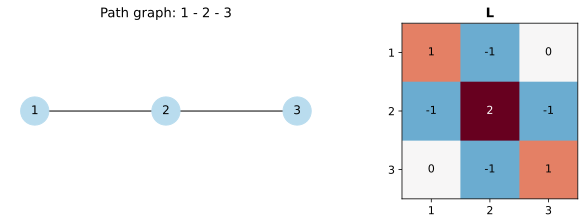

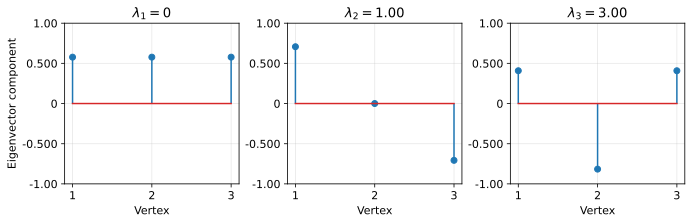

In [2]:
path3 = nx.path_graph(range(1, 4))
L3 = laplacian(path3)
values3, vectors3, tol3 = spectrum(L3)

print("ラプラシアン:")
pprint(L3.astype(int))
print("固有値（丸め誤差の範囲内の値だけ、表示上は0にする）:")
pprint(np.where(np.abs(values3) < tol3, 0, values3))

# 記号計算で特性多項式を照合し、数式として表示する。
lam = sp.Symbol("lambda")
symbolic_L = sp.Matrix(L3.astype(int))
polynomial = sp.factor((symbolic_L - lam * sp.eye(3)).det())
display(Latex(r"\(\det(\mathbf{L}-\lambda\mathbf{I})=" + sp.latex(polynomial) + r"\)"))
assert sp.expand(polynomial + lam * (lam - 1) * (lam - 3)) == 0
assert np.allclose(values3, [0, 1, 3])

# 固有方程式と辺ごとの二乗差を独立に確認する。
assert np.allclose(L3 @ vectors3, vectors3 * values3)
energies = np.array([
    sum((vectors3[i - 1, k] - vectors3[j - 1, k]) ** 2 for i, j in path3.edges)
    for k in range(3)
])
assert np.allclose(energies, values3)
print("辺ごとの二乗差の合計:")
pprint(np.where(np.abs(energies) < tol3, 0, energies))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
nx.draw_networkx(path3, pos={i: (i, 0) for i in path3}, ax=axes[0],
                 node_color="#b9dcee", node_size=800)
axes[0].set_title("Path graph: 1 - 2 - 3")
axes[0].set_axis_off()
axes[1].imshow(L3, cmap="RdBu_r", vmin=-2, vmax=2)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, str(int(L3[i, j])), ha="center", va="center",
                     color="white" if L3[i, j] == 2 else "black")
axes[1].set(xticks=range(3), xticklabels=range(1, 4),
            yticks=range(3), yticklabels=range(1, 4), title=r"$\mathbf{L}$")
show_figure(fig, "01_path_and_laplacian")

fig, axes = plt.subplots(1, 3, figsize=(9.50, 3), layout="constrained")
for k, ax in enumerate(axes):
    vector = vectors3[:, k].copy()
    vector *= 1 if vector[0] >= 0 else -1  # 手計算と符号を合わせる。
    ax.stem(range(1, 4), vector)
    value = 0 if abs(values3[k]) < tol3 else values3[k]
    ax.set(title=rf"$\lambda_{k + 1}={sig3(value)}$", xlabel="Vertex",
           xticks=range(1, 4), ylim=(-1, 1))
    ax.yaxis.set_major_formatter(tick_format)
    ax.grid(alpha=0.300)
axes[0].set_ylabel("Eigenvector component")
show_figure(fig, "02_eigenvectors")

## 4. ゼロ固有値は連結成分を数える

各行の和がゼロなので$\mathbf{L}\mathbf{1}=\mathbf{0}$である。また、$\mathbf{L}\mathbf{x}=\mathbf{0}$なら前節の二乗差の和がゼロとなり、正の重みを持つ辺では$x_i=x_j$でなければならない。この等式を辺に沿ってたどると、各連結成分の内部で値が一定になる。

逆に、成分ごとに一定の値を置けば$\mathbf{L}\mathbf{x}=\mathbf{0}$となる。成分数が$c$なら独立な定数を$c$個選べるため、ゼロ固有値の重複度は$c$である。固有値を昇順に並べると$0=\lambda_1\leq\lambda_2\leq\cdots\leq\lambda_n$であり、連結であることと$\lambda_2>0$は同値である。[1]

6頂点で比較する。数値計算のゼロ判定には許容値を設ける。極端に小さい正の固有値はゼロと区別できない。

[{'components': 1, 'graph': 'Connected', 'zero_eigenvalues': 1},
 {'components': 2, 'graph': 'Two components', 'zero_eigenvalues': 2},
 {'components': 3, 'graph': 'Three components', 'zero_eigenvalues': 3}]


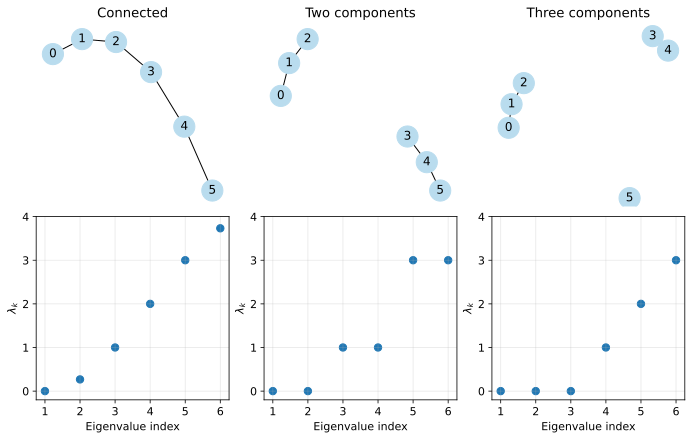

In [3]:
cases = {
    "Connected": nx.path_graph(6),
    "Two components": nx.disjoint_union(nx.path_graph(3), nx.path_graph(3)),
    "Three components": nx.disjoint_union_all([
        nx.path_graph(3), nx.path_graph(2), nx.empty_graph(1)
    ]),
}
fig, axes = plt.subplots(2, 3, figsize=(9.50, 6), layout="constrained")
summary = []
for column, (name, graph) in enumerate(cases.items()):
    values, _, tolerance = spectrum(laplacian(graph))
    zeros = int(np.count_nonzero(np.abs(values) < tolerance))
    components = nx.number_connected_components(graph)
    assert zeros == components
    summary.append({"graph": name, "components": components, "zero_eigenvalues": zeros})

    nx.draw_networkx(graph, pos=nx.spring_layout(graph, seed=101),
                     ax=axes[0, column], node_color="#b9dcee", node_size=450)
    axes[0, column].set_title(name)
    axes[0, column].set_axis_off()
    shown = np.where(np.abs(values) < tolerance, 0, values)
    axes[1, column].scatter(range(1, 7), shown, s=55)
    axes[1, column].set(xlabel="Eigenvalue index", ylabel=r"$\lambda_k$",
                       xticks=range(1, 7), ylim=(-0.200, 4))
    axes[1, column].yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1, column].grid(alpha=0.300)
pprint(summary)
show_figure(fig, "03_components_and_spectra")

## 5. 第2固有値と弱い接続

連結な場合、$\mathbf{u}_1=\mathbf{1}/\sqrt n$である。平均ゼロの$\mathbf{x}\ne\mathbf{0}$を$\mathbf{x}=\sum_{k=2}^n c_k\mathbf{u}_k$と展開する。正規直交性により、

$$
\frac{\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}}{\mathbf{x}^{\mathsf T}\mathbf{x}}
=\frac{\sum_{k=2}^n\lambda_k c_k^2}{\sum_{k=2}^n c_k^2}
\geq\frac{\lambda_2\sum_{k=2}^n c_k^2}{\sum_{k=2}^n c_k^2}=\lambda_2.
$$

$\mathbf{x}=\mathbf{u}_2$で等号となるため、

<div>

$$
\lambda_2=\min_{\mathbf{x}\ne\mathbf{0},\,\mathbf{x}^{\mathsf T}\mathbf{1}=0}
\frac{\sum_{\{i,j\}\in E}w_{ij}(x_i-x_j)^2}{\sum_i x_i^2}.
$$

</div>

$\lambda_2$は代数的連結度と呼ばれる。[2] 2個の三角形を重み$\varepsilon$の1本の辺で結び、片方の頂点に1、他方に$-1$を置く。内部の辺の差はゼロ、接続辺の差は2、値の二乗和は6なので、$\lambda_2\leq\varepsilon(1-(-1))^2/6=2\varepsilon/3$となる。

弱い接続があると、小さな変化量で両側に異なる値を置ける。図では$\mathbf{u}_2$の符号も両側に分かれる。ただし、全重みを$a>0$倍すると$\mathbf{L}$も固有値も$a$倍になる。異なるグラフの比較では、頂点数と重みの尺度をそろえる必要がある。

接続辺の重みと第2固有値:
{'lambda_2': '0.0638', 'weight': '0.100'}


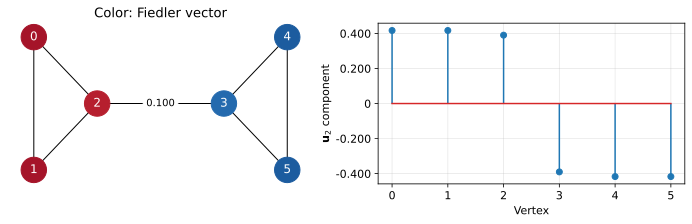

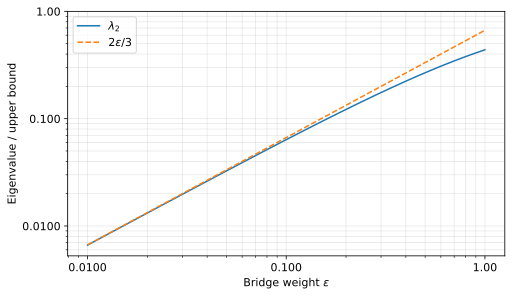

In [4]:
def joined_triangles(weight):
    graph = nx.disjoint_union(nx.complete_graph(3), nx.complete_graph(3))
    nx.set_edge_attributes(graph, 1, "weight")
    graph.add_edge(2, 3, weight=weight)
    return graph


bridge_weight = 0.100
bridge = joined_triangles(bridge_weight)
bridge_values, bridge_vectors, _ = spectrum(laplacian(bridge))
fiedler = bridge_vectors[:, 1]
fiedler *= 1 if fiedler[0] > 0 else -1
print("接続辺の重みと第2固有値:")
pprint({"weight": sig3(bridge_weight), "lambda_2": sig3(bridge_values[1])})

positions = {0: (0, 1), 1: (0, -1), 2: (1, 0),
             3: (3, 0), 4: (4, 1), 5: (4, -1)}
fig, axes = plt.subplots(1, 2, figsize=(9.50, 3), layout="constrained")
nx.draw_networkx(bridge, pos=positions, ax=axes[0], node_color=fiedler,
                 cmap=plt.cm.RdBu_r, vmin=-0.500, vmax=0.500, node_size=650, font_color="white")
nx.draw_networkx_edge_labels(bridge, positions, ax=axes[0],
                             edge_labels={(2, 3): sig3(bridge_weight)})
axes[0].set_title("Color: Fiedler vector")
axes[0].set_axis_off()
axes[1].stem(range(6), fiedler)
axes[1].set(xlabel="Vertex", ylabel=r"$\mathbf{u}_2$ component", xticks=range(6))
axes[1].yaxis.set_major_formatter(tick_format)
axes[1].grid(alpha=0.300)
show_figure(fig, "04_weak_bridge")

weights = np.geomspace(0.0100, 1, 60)
lambda2 = np.array([spectrum(laplacian(joined_triangles(w)))[0][1] for w in weights])
upper_bound = 2 * weights / 3
assert np.all(lambda2 <= upper_bound + 1e-12)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.loglog(weights, lambda2, label=r"$\lambda_2$")
ax.loglog(weights, upper_bound, "--", label=r"$2\varepsilon/3$")
ax.set(xlabel=r"Bridge weight $\varepsilon$", ylabel="Eigenvalue / upper bound")
ax.set_xticks([0.0100, 0.100, 1])
ax.set_yticks([0.0100, 0.100, 1])
ax.xaxis.set_major_formatter(tick_format)
ax.yaxis.set_major_formatter(tick_format)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.legend()
ax.grid(which="both", alpha=0.300)
show_figure(fig, "05_bridge_weight_and_lambda2")

## 6. 固有値は拡散の減衰率になる

各頂点の値が隣との差に比例して変化する拡散を考える。

$$
\frac{dx_i}{dt}=\sum_j w_{ij}(x_j-x_i)
=-(\mathbf{L}\mathbf{x})_i,\qquad
\frac{d\mathbf{x}}{dt}=-\mathbf{L}\mathbf{x}.
$$

$\mathbf{x}(t)=\sum_k c_k(t)\mathbf{u}_k$を代入し、両辺に$\mathbf{u}_k^{\mathsf T}$を掛けると$c_k'(t)=-\lambda_k c_k(t)$となる。積分因子を使えば、

$$
\frac{d}{dt}\{e^{\lambda_k t}c_k(t)\}=0
\quad\Rightarrow\quad
c_k(t)=c_k(0)e^{-\lambda_k t}.
$$

したがって、

<div>

$$
\mathbf{x}(t)=\sum_{k=1}^n
(\mathbf{u}_k^{\mathsf T}\mathbf{x}(0))e^{-\lambda_k t}\mathbf{u}_k.
$$

</div>

連結ならゼロ固有値の成分だけが残り、初期値の平均$\bar{x}$にそろう。平均からのずれは、正規直交性より

$$
\begin{aligned}
\|\mathbf{x}(t)-\bar{x}\mathbf{1}\|^2
&=\sum_{k=2}^n c_k(0)^2e^{-2\lambda_k t}\\
&\leq e^{-2\lambda_2t}\sum_{k=2}^n c_k(0)^2\\
&=e^{-2\lambda_2t}\|\mathbf{x}(0)-\bar{x}\mathbf{1}\|^2.
\end{aligned}
$$

両辺の平方根を取ると、ノルムの上界は$e^{-\lambda_2t}$で減衰する。最も遅い非定数成分の時定数は$1/\lambda_2$である。ただし、初期値にその成分がなければ、実際の収束はより速い。非連結なら各連結成分の平均に収束する。

第2固有値と時定数:
{'1 / lambda_2': '3.73', 'lambda_2': '0.268'}


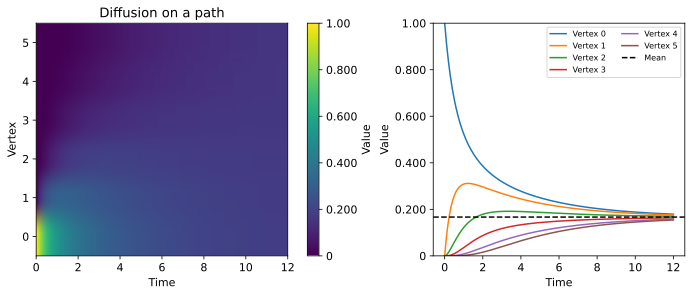

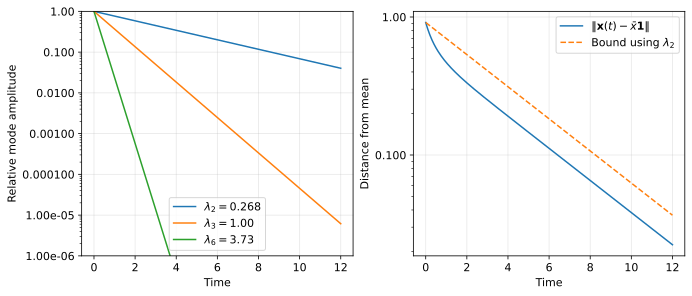

In [5]:
graph6 = nx.path_graph(6)
L6 = laplacian(graph6)
values6, vectors6, tolerance6 = spectrum(L6)
times = np.linspace(0, 12, 241)
initial = np.array([1, 0, 0, 0, 0, 0], dtype=float)
coefficients = vectors6.T @ initial

# 各固有成分を減衰させてから、頂点上の値に戻す。
decay = np.exp(-values6[:, None] * times[None, :])
states = vectors6 @ (coefficients[:, None] * decay)
assert np.allclose(states[:, 0], initial)
assert np.allclose(states.sum(axis=0), initial.sum())
assert np.allclose(states[:, 60], expm(-L6 * times[60]) @ initial)
print("第2固有値と時定数:")
pprint({"lambda_2": sig3(values6[1]), "1 / lambda_2": sig3(1 / values6[1])})

fig, axes = plt.subplots(1, 2, figsize=(9.50, 4), layout="constrained")
heatmap = axes[0].imshow(states, aspect="auto", origin="lower", cmap="viridis",
                         extent=[times[0], times[-1], -0.500, 5.50], vmin=0, vmax=1)
axes[0].set(xlabel="Time", ylabel="Vertex", yticks=range(6), title="Diffusion on a path")
fig.colorbar(heatmap, ax=axes[0], format=tick_format, label="Value")
for vertex in range(6):
    axes[1].plot(times, states[vertex], label=f"Vertex {vertex}")
axes[1].axhline(initial.mean(), color="black", linestyle="--", label="Mean")
axes[1].set(xlabel="Time", ylabel="Value", ylim=(0, 1))
axes[1].yaxis.set_major_formatter(tick_format)
axes[1].legend(ncol=2, fontsize=8)
show_figure(fig, "06_diffusion")

distance = np.linalg.norm(states - initial.mean(), axis=0)
bound = np.linalg.norm(initial - initial.mean()) * np.exp(-values6[1] * times)
assert np.all(distance <= bound + 1e-12)
fig, axes = plt.subplots(1, 2, figsize=(9.50, 4), layout="constrained")
for k in (1, 2, 5):
    axes[0].semilogy(times, decay[k], label=rf"$\lambda_{k + 1}={sig3(values6[k])}$")
axes[0].set(xlabel="Time", ylabel="Relative mode amplitude", ylim=(1e-6, 1))
axes[1].semilogy(times, distance, label=r"$\|\mathbf{x}(t)-\bar{x}\mathbf{1}\|$")
axes[1].semilogy(times, bound, "--", label=r"Bound using $\lambda_2$")
axes[1].set(xlabel="Time", ylabel="Distance from mean")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.300)
    ax.yaxis.set_major_formatter(tick_format)
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
show_figure(fig, "07_decay_rates")

## 結論

この記事では、グラフラプラシアンの固有値を、辺上の変化量、連結成分数、拡散の減衰率として確認した。

ゼロ固有値の個数は連結成分数に等しい。第2固有値は平均ゼロの値の並びに対する最小の変化量であり、連結なグラフでは拡散の遅い成分を決める。正規化した行列では固有値や平均の扱いが変わる。

参考文献：[1] Spielman, [The Laplacian (2009)](https://www.cs.yale.edu/homes/spielman/561/2009/lect02-09.pdf)。[2] 同著者、[The Laplacian (2015)](https://www.cs.yale.edu/homes/spielman/561/lect02-15.pdf)。[SciPy公式資料：eigh](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.eigh.html)。